# Task 3: Real-Time Echocardiogram Video Analysis

In [1]:
import os
import sys
import time
import cv2
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 55

DATA_DIR = "data"
OUT_DIR = "output"
os.makedirs(OUT_DIR, exist_ok=True)


def to_rgb(img):
    return img if img.ndim == 2 else cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


def show(ax, img, title):
    ax.imshow(to_rgb(img), cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")


def save(name, img):
    cv2.imwrite(os.path.join(OUT_DIR, name), img)


def to_gray(img):
    return img if img.ndim == 2 else cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)


def entropy_bits(img):
    p = np.bincount(to_gray(img).ravel(), minlength=256).astype(np.float64)
    p /= p.sum()
    p = p[p > 0]
    return float(-(p * np.log2(p)).sum())


def stats(name, img):
    g = to_gray(img)
    lo, hi = np.percentile(g, [1, 99])
    print(f"{name:30s} mean {g.mean():6.1f}   std {g.std():6.1f}   1-99% range {hi - lo:5.0f}   entropy {entropy_bits(g):5.2f} bits")


def log_lut(k=255.0):
    x = np.arange(256, dtype=np.float32) / 255.0
    return np.clip(255.0 * np.log1p(k * x) / np.log1p(k), 0, 255).astype(np.uint8)


def power_lut(gamma):
    x = np.arange(256, dtype=np.float32) / 255.0
    return np.clip(255.0 * x ** gamma, 0, 255).astype(np.uint8)


def log_transform(img, k=255.0):
    return cv2.LUT(img, log_lut(k))


def power_law(img, gamma):
    return cv2.LUT(img, power_lut(gamma))


def gray_world_gains(bgr, valid=None):
    px = bgr.reshape(-1, 3).astype(np.float64)
    if valid is not None:
        px = px[valid.ravel()]
    means = px.mean(axis=0)
    return means.mean() / means


def apply_gains(bgr, gains):
    return np.clip(bgr.astype(np.float32) * gains.astype(np.float32), 0, 255).astype(np.uint8)

VIDEO = os.path.join(DATA_DIR, "echo_sample.mp4")
GAMMA = 1.5
SNAP_FRAMES = (0, 30, 60)
MAX_FRAMES = None
SHOW = sys.platform in ("win32", "darwin") or bool(os.environ.get("DISPLAY"))
LOG_LUT = log_lut()
POWER_LUT = power_lut(GAMMA)
print("OpenCV", cv2.__version__, "| live window:", SHOW)


OpenCV 5.0.0 | live window: False


## 1. Per-frame enhancement pipeline

In [2]:
class ColorBalancer:
    def __init__(self, smoothing=0.9):
        self.smoothing = smoothing
        self.gains = None

    def __call__(self, bgr, valid):
        g = gray_world_gains(bgr, valid)
        self.gains = g if self.gains is None else self.smoothing * self.gains + (1 - self.smoothing) * g
        return apply_gains(bgr, self.gains)


def enhance_frame(frame, balancer, return_stages=False):
    gray = to_gray(frame)
    equalized = cv2.equalizeHist(gray)
    heatmap = cv2.applyColorMap(equalized, cv2.COLORMAP_JET)
    balanced = balancer(heatmap, gray > 0)
    logged = cv2.LUT(balanced, LOG_LUT)
    final = cv2.LUT(logged, POWER_LUT)
    if return_stages:
        return final, [gray, equalized, heatmap, balanced, logged, final]
    return final


def label(img, text):
    out = img.copy()
    cv2.putText(out, text, (10, 24), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 255), 2, cv2.LINE_AA)
    return out


## 2. Video capture and real-time loop

In [3]:
cap = cv2.VideoCapture(VIDEO)
if not cap.isOpened():
    raise FileNotFoundError(VIDEO)
fps = cap.get(cv2.CAP_PROP_FPS) or 30.0
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
print(f"source: {VIDEO}, {width}x{height}, {fps:.0f} FPS, {total} frames")

writer = cv2.VideoWriter(os.path.join(OUT_DIR, "echo_side_by_side.mp4"), cv2.VideoWriter_fourcc(*"mp4v"), fps, (width * 2, height))
balancer = ColorBalancer()
times, snaps, stage_frame = [], {}, None
index = 0
while True:
    ok, frame = cap.read()
    if not ok:
        break
    start = time.perf_counter()
    enhanced, stages = enhance_frame(frame, balancer, return_stages=True)
    times.append(time.perf_counter() - start)
    panel = np.hstack([label(frame, "Raw ultrasound"), label(enhanced, "Enhanced")])
    writer.write(panel)
    if index in SNAP_FRAMES:
        cv2.imwrite(os.path.join(OUT_DIR, f"frame_{index:03d}_side_by_side.png"), panel)
        snaps[index] = panel
    if index == SNAP_FRAMES[1]:
        stage_frame = stages
    if SHOW:
        cv2.imshow("Echocardiogram: raw | enhanced (press q to quit)", panel)
        if cv2.waitKey(max(1, int(1000 / fps))) & 0xFF == ord("q"):
            break
    index += 1
    if MAX_FRAMES is not None and index >= MAX_FRAMES:
        break

cap.release()
writer.release()
if SHOW:
    cv2.destroyAllWindows()

times = np.array(times)
print(f"frames processed: {index}")
print(f"mean enhancement time per frame: {times.mean() * 1000:.2f} ms  ->  up to {1.0 / times.mean():.0f} FPS (video is {fps:.0f} FPS)")


source: data/echo_sample.mp4, 320x320, 30 FPS, 90 frames


frames processed: 90
mean enhancement time per frame: 2.82 ms  ->  up to 355 FPS (video is 30 FPS)


## 3. Saved screenshots and stage-by-stage view

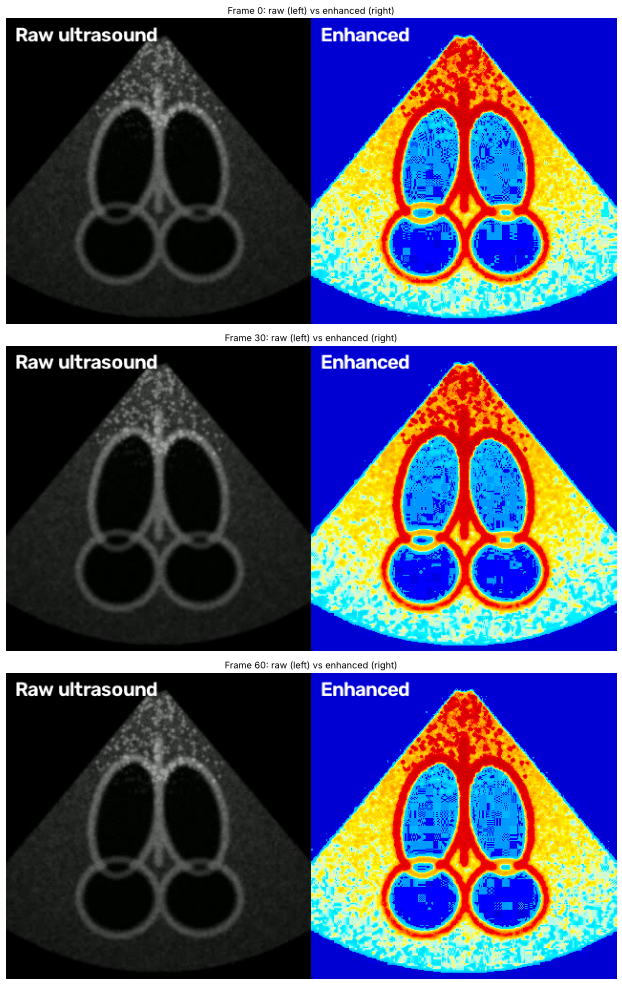

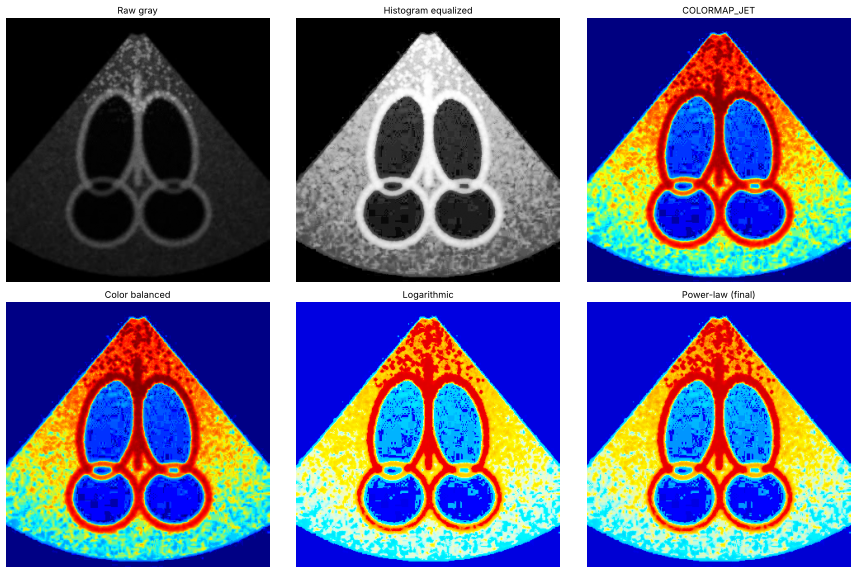

Raw gray                       mean   20.4   std   27.1   1-99% range   114   entropy  4.64 bits
Histogram equalized            mean   82.5   std   85.0   1-99% range   251   entropy  4.56 bits
COLORMAP_JET                   mean   85.4   std   75.7   1-99% range   211   entropy  4.47 bits
Color balanced                 mean   83.3   std   73.2   1-99% range   204   entropy  4.47 bits
Logarithmic                    mean  111.1   std   86.1   1-99% range   216   entropy  4.35 bits
Power-law (final)              mean  105.7   std   83.2   1-99% range   212   entropy  4.41 bits


In [4]:
fig, axes = plt.subplots(len(snaps), 1, figsize=(12, 6 * len(snaps)))
for ax, (i, panel) in zip(np.atleast_1d(axes), snaps.items()):
    show(ax, panel, f"Frame {i}: raw (left) vs enhanced (right)")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "side_by_side_screenshots.png"), dpi=80)
plt.show()

names = ["Raw gray", "Histogram equalized", "COLORMAP_JET", "Color balanced", "Logarithmic", "Power-law (final)"]
fig, axes = plt.subplots(2, 3, figsize=(16, 10.5))
for ax, name, img in zip(axes.ravel(), names, stage_frame):
    show(ax, img, name)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "pipeline_stages.png"), dpi=80)
plt.show()

for name, img in zip(names, stage_frame):
    stats(name, img)


## Summary

The pipeline (gray, equalization, JET, color balance, log, power-law) processes all 90 frames at about 3.00 ms per frame, roughly 334 FPS against the 30 FPS source, so real-time playback is feasible. Side-by-side video and screenshots of frames 0, 30 and 60 are saved in `output/`.